In [1]:
import casadi as cs
import numpy as np
from scipy.optimize import brentq
from time import perf_counter
from matplotlib import pyplot as plt
import pickle

In [2]:
data = pickle.load(open('../data/dataset_2/dataset_21.pkl','rb'))
K = data["K"]
W = data["W"]
Nf = data["Nf"]
Ns = data["Ns"]
locomotion_NMM = np.array(data["locomotion"][2])
switching_NMM = np.array(data["switch"][2])
Emin = max(min(locomotion_NMM[:,-1]),min(switching_NMM[:,-1]))
Emax = min(max(locomotion_NMM[:,-1]),max(switching_NMM[:,-1]))

print(r"k = {} | w = {}".format(K,W))
print("E in [{:.2f},{:.2f}]".format(Emin,Emax))

k = 15.555555555555555 | w = 0.9444444444444444
E in [2.38,7.77]


In [3]:
def energy_sample(M,grid):
    idx = np.argsort(M[:,-1])
    M = M[idx,:]
    E = M[:,-1]
    return np.column_stack([np.interp(grid, E, M[:, c]) for c in range(M.shape[1])])

In [4]:
E_grid = np.linspace(Emin, Emax, 20)
locomotion_NMM_sampled = energy_sample(locomotion_NMM,E_grid)
switching_NMM_sampled = energy_sample(switching_NMM,E_grid)


In [5]:
def RK4(f,x,h,u):
    k1 = f(x,u)
    k2 = f(x+0.5*h*k1,u)
    k3 = f(x+0.5*h*k2,u)
    k4 = f(x+h*k3,u)
    x_next = x + h/6 * (k1 + 2*k2 + 2*k3 +k4)
    return x_next


In [6]:
xs = cs.SX.sym("xs", 4)
xf = cs.SX.sym("xf", 6)
u = cs.SX.sym("u")
h = cs.SX.sym("h")

l = cs.sqrt(xs[0] ** 2 + xs[1] ** 2)
dxs = cs.vertcat(
    xs[2:], 
    (K * (1 - l) + u) * xs[0] / l, 
    (K * (1 - l) + u) * xs[1] / l - 1
)
dxf = cs.vertcat(
    xf[3:], 
    0, 
    -1, 
    -(W**2) * xf[2] + u
)
xfs = cs.vertcat(
    xs[:2],
    cs.atan2(-xs[0],xs[1]),
    xs[2:],
    (xs[0] * xs[3] - xs[1] * xs[2]) / l**2
)
xsf = cs.vertcat(
    -cs.sin(xf[2]),
    xf[[1,3,4]]
)
e_TD = cs.cos(xf[2]) - xf[1]
e_LO = l - 1
de_TD = -cs.sin(xf[2])*xf[5] - xf[3]
de_LO = xs[0]*xs[2] + xs[1]*xs[3]


In [7]:
f =  {
    "f": cs.Function("ff", [xf, u], [dxf]), 
    "s": cs.Function("fs", [xs, u], [dxs])
}
rk4 = {
    "f": cs.Function("RK4f", [xf,h,u],[RK4(f["f"],xf,h,u)]),
    "s": cs.Function("RK4s", [xs,h,u],[RK4(f["s"],xs,h,u)])
}
convert = {
    "s": cs.Function("to_flight", [xs],[xfs]),
    "f": cs.Function("to_stance", [xf],[xsf])
}
guard = {
    "s" : cs.Function("guards", [xs], [e_LO]),
    "f" : cs.Function("guardf", [xf], [e_TD])
}
guard_rate = {
    "s" : cs.Function("guards", [xs], [de_LO]),
    "f" : cs.Function("guardf", [xf], [de_TD])
}
next_mode = {
    "f":"s", 
    "s":"f"
}
dim = {
    "f":6, 
    "s":4
}

In [8]:
def integrate_until_event(x0,mode,N_max=1000,h=1e-2):
    x = x0
    t = 0.0
    xh = []
    th = []
    armed = False
    
    for i in range(N_max):

        xh.append(x)
        th.append(t)
        x_next = rk4[mode](x,h,0.0)

        g0 = guard[mode](x)
        g1 = guard[mode](x_next)

        if (not armed) and g1 < 0 and g0<0:
            armed = True

        if g0 * g1 < 0 and armed:
            def residual(tau):
                x_tau = rk4[mode](x,tau,0.0)
                return guard[mode](x_tau)
            
            tau_event = brentq(residual,0.0,h,xtol=1e-6,rtol=1e-6)
            x_event = rk4[mode](x,tau_event,0.0)
            xh.append(x_event)
            th.append(t+tau_event)

            return np.column_stack(th),np.column_stack(xh)

        t += h
        x = x_next

    return np.column_stack(th),np.column_stack(xh)


In [9]:
def trajectory_sample(u,grid):
    x0 = u[:6]
    th,xh = integrate_until_event(x0,"f")
    tTD,xTD = th[0,-1],convert["f"](xh[:,-1])
    th_s,xh_s = integrate_until_event(xTD,"s")
    tLO,xLO = th_s[0,-1],convert["s"](xh_s[:,-1])
    th_f,xh_f = integrate_until_event(xLO,"f")
    ts_norm = th_s / th_s[0,-1]
    tf_norm = th_f / th_f[0,-1] 

    traj_s = np.column_stack([
        np.interp(grid, ts_norm.squeeze(), xh_s[r,:]) for r in range(xh_s.shape[0])
    ]+[np.interp(grid, ts_norm.squeeze(), th_s.squeeze())])
    traj_f = np.column_stack([
        np.interp(grid, tf_norm.squeeze(), xh_f[r,:]) for r in range(xh_f.shape[0])
    ]+[np.interp(grid, tf_norm.squeeze(), th_f.squeeze())])
    # traj_s = convert["s"](traj_s.T).T

    return traj_s,traj_f

In [10]:
def surface(M,grid):
    N = M.shape[0]
    surf_s,surf_f = np.zeros((N,N,5)),np.zeros((N,N,7))
    for i in range(N):
        ts,tf = trajectory_sample(M[i],grid)
        surf_s[:,i,:] = ts
        surf_f[:,i,:] = tf
    return surf_s,surf_f

In [11]:
phi_grid = np.linspace(0,1,20)
ss_loc,sf_loc = surface(locomotion_NMM_sampled,phi_grid)
ss_swi,sf_swi = surface(switching_NMM_sampled,phi_grid)

values_sloc = ss_loc.ravel(order="C")
values_floc = sf_loc.ravel(order="C")
values_sswi = ss_swi.ravel(order="C")
values_fswi = sf_swi.ravel(order="C")
LUT_sloc = cs.interpolant('LUT_sloc', 'bspline',[E_grid,phi_grid],values_sloc)
LUT_floc = cs.interpolant('LUT_floc', 'bspline',[E_grid,phi_grid],values_floc)
LUT_sswi = cs.interpolant('LUT_sswi', 'bspline',[E_grid,phi_grid],values_sswi)
LUT_fswi = cs.interpolant('LUT_fswi', 'bspline',[E_grid,phi_grid],values_fswi)

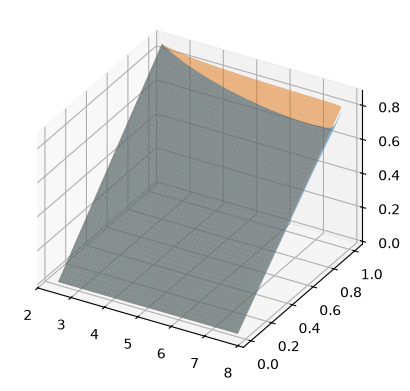

In [12]:
phi_linspace = np.linspace(0,1,100)
E_linspace = np.linspace(Emin,Emax,100)
sloc_fancy = np.zeros((100,100,5))
sswi_fancy = np.zeros((100,100,5))
X1,X2 = np.meshgrid(E_linspace,phi_linspace)
for i in range(100):
    for j in range(100):
        sloc_fancy[i,j] = np.array(LUT_sloc([E_linspace[i],phi_linspace[j]])).squeeze()
        sswi_fancy[i,j] = np.array(LUT_sswi([E_linspace[i],phi_linspace[j]])).squeeze()

fig = plt.figure()
ax = fig.add_subplot(1,1,1,projection='3d')
ax.set_proj_type('ortho')
# ax.plot_surface(ss_loc[:,:,1],ss_loc[:,:,2],ss_loc[:,:,3])
ax.plot_surface(X1,X2,sloc_fancy[:,:,-1].T,alpha=0.5)
ax.plot_surface(X1,X2,sswi_fancy[:,:,-1].T,alpha=0.5)
# ax.view_init(elev=20, azim=45)
plt.show()


In [13]:
class Solver:

    def __init__(self,LUT,N,K,W,Emin,Emax,modes):
        self.LUT = LUT
        self.N = N
        self.K = K
        self.W = W
        self.modes = modes
        self.event_margin = 1e-3
        self.terminal_validity = 0.01

        # create solver instance using casadi opti stack
        opts = {"print_time": 0, "ipopt.print_level": 0, "ipopt.tol": 1e-6}
        self.opti = cs.Opti()
        self.opti.solver("ipopt", opts)

        self.T = self.opti.parameter()
        self.E_bar = self.opti.parameter()
        self.x0 = self.opti.parameter(dim[modes[0]])
        self.x = [self.opti.variable(dim[m],N[m]) for m in modes]
        self.u = [self.opti.variable(N[m]-1) for m in modes]
        self.t = [self.opti.variable() for _ in range(len(modes))]
        self.h = [self.t[i] / (N[modes[i]]-1) for i in range(len(modes))]

        self.e = self.opti.variable()
        self.phi = self.opti.variable()

        self.opti.subject_to(self.opti.bounded(Emin, self.e, Emax))
        self.opti.subject_to(self.opti.bounded(self.terminal_validity, self.phi, 1.0))
        self.opti.subject_to(sum(self.t) == self.T)

        self.constrain()

    def constrain(self):
        self.Ju = 0

        # initial constaint
        self.opti.subject_to(self.x[0][:,0] == self.x0)

        for idx in range(len(self.modes)):
            # dynamics constraint
            m = self.modes[idx]
            self.add_dynamics(m,self.x[idx], self.u[idx], self.h[idx])

            # running cost
            self.Ju += self.h[idx] * cs.sumsqr(self.u[idx])

        for idx in range(len(self.modes)-1):
            # intra-step continuity
            m = self.modes[idx]
            self.opti.subject_to(self.x[idx+1][:,0] == convert[m](self.x[idx][:,-1]))

            # event crossing
            self.opti.subject_to(guard[m](self.x[idx][:,-1]) == 0)
            self.opti.subject_to(guard_rate[m](self.x[idx][:,-1]) >= self.event_margin)

        # terminal constraint
        self.opti.subject_to(guard[self.modes[-1]](self.x[-1][:,1:]) < 0)
        if self.modes[-1] == "f":
            self.r = self.LUT(cs.vertcat(self.e,self.phi))[1:-1] - self.x[-1][1:,-1]
        else: 
            self.r = self.LUT(cs.vertcat(self.e,self.phi))[:-1] - self.x[-1][:,-1]
        self.opti.subject_to(cs.sumsqr(self.r) <= (1e-3)**2)

        self.opti.minimize(self.Ju + 10*(self.e - self.E_bar)**2)


    def add_dynamics(self,m , x, u, h):
        for k in range(self.N[m]-1):
            self.opti.subject_to(x[:, k + 1] == rk4[m](x[:, k], h, u[k]))


    def initialize(self,x,u,t,T,x0,E0,phi0):
        self.opti.set_value(self.x0,x0)
        self.opti.set_value(self.T,T)
        self.opti.set_value(self.E_bar,E0)
        self.opti.set_initial(self.e, E0)
        self.opti.set_initial(self.phi, phi0)
        for idx in range(len(self.modes)):
            self.opti.set_initial(self.x[idx], x[idx])
            self.opti.set_initial(self.u[idx], u[idx])
            self.opti.set_initial(self.t[idx], t[idx])

    def solve(self):
        try:
            start = perf_counter()
            sol = self.opti.solve_limited()
            end = perf_counter()
            return {
                        "x": [sol.value(X) for X in self.x],
                        "u": [sol.value(U) for U in self.u],
                        "t": [sol.value(T) for T in self.t],
                        "E": sol.value(self.e),
                        "phi": sol.value(self.phi),
                        "cost":sol.value(self.Ju),
                        "wall-time":end-start,
                        "success":sol.stats()["success"],
                        "iterations":sol.stats()["iter_count"]
                    }        
        except RuntimeError:
            return {"success":False}
    

In [14]:
def initialize_mode(m,LUT,N,E0,phi_end=1.0):
    grid = np.linspace(0,phi_end,N)
    x_init = np.zeros((dim[m],N))
    for i in range(N):
        x_init[:,i] = np.array(LUT([E0,grid[i]])[:-1]).squeeze()
    return x_init


In [ ]:
E0 = Emin+0.2
E_inf = max(Emin,E0-0.2)
E_sup = min(Emax,E0+0.2)
N = {"s":20,"f":15}
modes = ["s","f","s"]
solver = Solver(LUT_sloc,N,K,W,E_inf,E_sup,modes)

ts,tf = LUT_sloc([E0,1])[-1],LUT_floc([E0,1])[-1]
T_init = ts + tf + 0.25*ts
xs_init = initialize_mode("s",LUT_sloc,N["s"],E0) ## TODO use rk4 instead
xf_init = initialize_mode("f",LUT_floc,N["f"],E0)
solver.initialize(
    [xs_init,xf_init,initialize_mode("s",LUT_sloc,N["s"],E0,0.5)],
    [np.zeros((N[m]-1,)) for m in modes],
    [ts,tf,0.5*ts],
    T_init,
    xs_init[:,0],
    E0,
    1 
)
sol = solver.solve()


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



In [16]:
print(xf_init[:,-1],cs.cos(xf_init[2,-1]))

[ 2.34736664  0.97149494  0.22575786  0.63851338 -1.66319365  0.24719283] 0.974624744583387


0.0972637594149529 0.0830177308591189 5.514976830218022 2.5725196890578275 2.5831111611476305


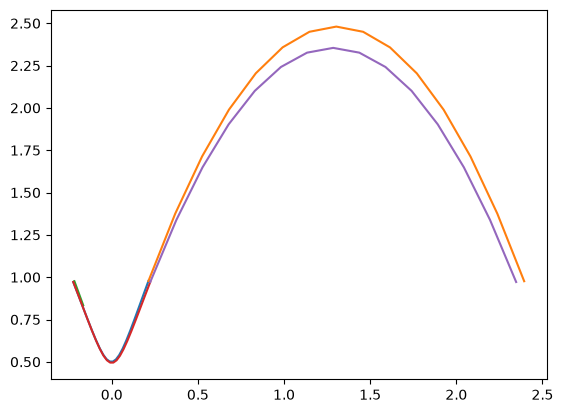

In [17]:
xh = sol["x"]
print(sol["phi"],sol["t"][-1],sol["cost"],sol["E"],E0)
for t in xh:
    plt.plot(t[0,:],t[1,:])
for t in [xs_init,xf_init]:
    plt.plot(t[0,:],t[1,:])